<a href="https://colab.research.google.com/github/rajaiikram19-a11y/Text_classification/blob/main/Text_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Objective

**Build a model that can Classify documents and categorise them into different classes**

## Install necessary libraries

In [ ]:
%%time

# Installation des bibliothèques nécessaires avec des versions compatibles modernes
!pip install scikit-learn matplotlib seaborn pmdarima portalocker>=2.0.0 plotly dash
!pip install numpy pandas
!pip install torch torchtext torchdata torchvision torchaudio

CPU times: user 6.24 s, sys: 1.53 s, total: 7.77 s
Wall time: 29.6 s


In [ ]:
# Cellule de secours simplifiée sans contraintes de versions obsolètes
%pip install numpy pandas
%pip install torch torchtext torchdata torchvision torchaudio

In [ ]:
%pip install torch==2.3.0 torchtext==0.18.0 torchdata==0.7.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 779.1/779.1 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 184.4/184.4 kB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 28.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 731.7/731.7 MB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 MB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.2/124.2 MB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.0/196.0 MB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
%pip install torch==2.3.0 torchtext==0.18.0 torchdata==0.7.1 torchvision==0.18.0 torchaudio==2.3.0


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 88.0 MB/s eta 0:00:00
  Attempting uninstall: torchvision
    Found existing installation: torchvision 0.24.0+cpu
    Uninstalling torchvision-0.24.0+cpu:
      Successfully uninstalled torchvision-0.24.0+cpu
  Attempting uninstall: torchaudio
    Found existing installation: torchaudio 2.9.0+cpu
    Uninstalling torchaudio-2.9.0+cpu:
      Successfully uninstalled torchaudio-2.9.0+cpu


## Import libraries

In [ ]:
from tqdm import tqdm
import numpy as np
import pandas as pd
from itertools import accumulate
import matplotlib.pyplot as plt
from torchtext.data.utils import get_tokenizer

import torch
import torch.nn as nn

from torch.utils.data import DataLoader
import numpy as np
from torchtext.datasets import AG_NEWS
from IPython.display import Markdown as md
from tqdm import tqdm

from torchtext.vocab import build_vocab_from_iterator
from torchtext.datasets import AG_NEWS
from torch.utils.data.dataset import random_split
from torchtext.data.functional import to_map_style_dataset
from sklearn.manifold import TSNE
import plotly.graph_objs as go
from sklearn.model_selection import train_test_split

from torchtext.data.utils import get_tokenizer

# You can also use this section to suppress warnings generated by your code:
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn
warnings.filterwarnings('ignore')

/usr/local/lib/python3.12/dist-packages/torchtext/data/__init__.py:4: UserWarning: 
/!\ IMPORTANT WARNING ABOUT TORCHTEXT STATUS /!\ 
Torchtext is deprecated and the last released version will be 0.18 (this one). You can silence this warning by calling the following at the beginnign of your scripts: `import torchtext; torchtext.disable_torchtext_deprecation_warning()`
  warnings.warn(torchtext._TORCHTEXT_DEPRECATION_MSG)
/usr/local/lib/python3.12/dist-packages/torchtext/datasets/__init__.py:4: UserWarning: 
/!\ IMPORTANT WARNING ABOUT TORCHTEXT STATUS /!\ 
Torchtext is deprecated and the last released version will be 0.18 (this one). You can silence this warning by calling the following at the beginnign of your scripts: `import torchtext; torchtext.disable_torchtext_deprecation_warning()`
  warnings.warn(torchtext._TORCHTEXT_DEPRECATION_MSG)
/usr/local/lib/python3.12/dist-packages/torchtext/vocab/__init__.py:4: UserWarning: 
/!\ IMPORTANT WARNING ABOUT TORCHTEXT STATUS /!\ 
Torchtext i

## Helper functions

In [ ]:

def plot(COST,ACC):
    fig, ax1 = plt.subplots()
    color = 'tab:red'
    ax1.plot(COST, color=color)
    ax1.set_xlabel('epoch', color=color)
    ax1.set_ylabel('total loss', color=color)
    ax1.tick_params(axis='y', color=color)

    ax2 = ax1.twinx()
    color = 'tab:blue'
    ax2.set_ylabel('accuracy', color=color)  # you already handled the x-label with ax1
    ax2.plot(ACC, color=color)
    ax2.tick_params(axis='y', color=color)
    fig.tight_layout()  # otherwise the right y-label is slightly clipped

    plt.show()


## Data preparation for the model

In [ ]:
# Injection d'un correctif de compatibilité pour corriger l'ImportError de DILL_AVAILABLE
import sys
import torch

try:
    import torch.utils.data.datapipes.utils.common as common
    if not hasattr(common, 'DILL_AVAILABLE'):
        common.DILL_AVAILABLE = True
except ImportError:
    pass

# Chargement du jeu de données
train_iter = iter(AG_NEWS(split="train"))

In [ ]:
y,text= next((train_iter))
print(y,text)

3 Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.


In [ ]:
ag_news_label = {1: "World", 2: "Sports", 3: "Business", 4: "Sci/Tec"}
ag_news_label[y]

'Business'

In [ ]:
num_class = len(set([label for (label, text) in train_iter ]))
num_class

4

In [ ]:

# 1.Reinitialize train_iter , the dataset
train_iter = AG_NEWS(split="train")

# 2.Define tokenizer and yield_tokens
tokenizer = get_tokenizer("basic_english")   #"basic_english": means which tokenization rules to use. It applies basic English text processing, such as converting text to lowercase and splitting words and punctuation.
#tokenizer("Hello, World!") =  ['hello', ',', 'world', '!']


def yield_tokens(data_iter):
    for _, text in data_iter:
        yield tokenizer(text.lower())  # Lowercase conversion for consistency


# 3.Build vocabulary
vocab = build_vocab_from_iterator(yield_tokens(train_iter), specials=["<unk>"])
vocab.set_default_index(vocab["<unk>"])


# Print the vocabulary size and sample tokens
print(f"Vocabulary size: {len(vocab)}")
print(f"Sample tokens: {list(vocab.get_stoi().keys())[:10]}")  # why this ,so we can have this: train_dataset[0]  # Get the first training example,  train_dataset[1]  # Get the second training example



Vocabulary size: 95811
Sample tokens: ['zzz', 'zygmunt', 'zwiki', 'zvidauri', 'zurine', 'zurab', 'zuo', 'zuloaga', 'zovko', 'zotinca']


 **tokenizer:** splits text into tokens.

 **vocabulary:**: assigns each token an index.

**set_default_index():** handles words missing from the vocabulary.

In [ ]:
vocab(["age","hello"])

[2120, 12544]

# Dataset

In [ ]:

# Split the dataset into training and testing iterators.
train_iter, test_iter = AG_NEWS()

# Convert the training and testing iterators to map-style datasets. (#why ? because It allows PyTorch's DataLoader to retrieve and organize examples into batches for training and testing)
train_dataset = to_map_style_dataset(train_iter) # # why this ,so we can have this: train_dataset[0]  # Get the first training example,  train_dataset[1]  # Get the second training example
test_dataset = to_map_style_dataset(test_iter)

# Determine the number of samples to be used for training and validation (5% for validation).
num_train = int(len(train_dataset) * 0.95)

# Randomly split the training dataset into training and validation datasets using `random_split`.
# The training dataset will contain 95% of the samples, and the validation dataset will contain the remaining 5%.
split_train_, split_valid_ = random_split(train_dataset, [num_train, len(train_dataset) - num_train])


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

# Data loader

In [ ]:

def text_pipeline(x):
  return vocab(tokenizer(x))

def label_pipeline(x):
   return int(x) - 1


The **offsets** tell the model where each article starts.

In [ ]:

# It prepares a batch of news articles for the model.
def collate_batch(batch):
    label_list, text_list, offsets = [], [], [0]
    for _label, _text in batch:
        label_list.append(label_pipeline(_label))
        processed_text = torch.tensor(text_pipeline(_text), dtype=torch.int64)
        text_list.append(processed_text)
        offsets.append(processed_text.size(0))
    label_list = torch.tensor(label_list, dtype=torch.int64)
    offsets = torch.tensor(offsets[:-1]).cumsum(dim=0)   #-1 means remove last number and cumsum means for example in this: [0, 3, 2] so for article 1: 0, article2:0+3 and for article 3: 0+3+2
    text_list = torch.cat(text_list) # we concatenate the lists of indexes or each article text
    return label_list.to(device), text_list.to(device), offsets.to(device)



In [ ]:
BATCH_SIZE = 64

train_dataloader = DataLoader(
    split_train_, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch
)
valid_dataloader = DataLoader(
    split_valid_, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch
)
test_dataloader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch
)

**shuffle=True:** randomly changes the order of articles each epoch.

**collate_fn=collate_batch:** applies your function to prepare each batch by converting the texts and labels into tensors and calculating offsets.

In [ ]:
label, text, offsets=next(iter(valid_dataloader ))
label, text, offsets

(tensor([0, 3, 2, 0, 0, 2, 2, 3, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 3, 0, 0, 3, 3, 2,
         3, 0, 0, 0, 1, 3, 3, 3, 0, 2, 0, 0, 1, 1, 1, 3, 3, 3, 2, 2, 0, 2, 2, 2,
         0, 0, 2, 3, 3, 1, 3, 2, 3, 2, 0, 3, 2, 3, 1, 2]),
 tensor([10461,   173,   196,  ...,     1,     9,     1]),
 tensor([   0,   41,   83,  115,  161,  187,  226,  273,  307,  354,  392,  425,
          479,  528,  565,  595,  628,  658,  686,  726,  780,  827,  846,  888,
          936,  976, 1026, 1063, 1101, 1138, 1196, 1239, 1296, 1338, 1390, 1433,
         1457, 1501, 1535, 1579, 1640, 1662, 1707, 1747, 1779, 1863, 1901, 1948,
         1981, 2018, 2057, 2095, 2166, 2194, 2247, 2278, 2323, 2372, 2416, 2473,
         2522, 2556, 2597, 2643]))

## Model
# Neural network

In [ ]:
from torch import nn

#nn.Module: the base class for PyTorch neural networks.
class TextClassificationModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, num_class):
        super(TextClassificationModel, self).__init__()
        self.embedding = nn.EmbeddingBag(vocab_size, embed_dim, sparse=False) #This layer takes token IDs and converts them into learned numerical vectors, then combines the vectors for each article into one vector. so vocab size is size of the phrase that we have or text, then embed_dim is dimension of token of each word then these token will be transformed to vectors then these vectors will be concatenated to one vector which will represent this article.so in general EmbeddingBag combines the word vectors for each article, typically by taking their average by default. This gives us one fixed-size vector per article, even when articles have different lengths.
        # sparse=False means the embedding gradients are represented as dense tensors rather than sparse tensors.
        self.fc = nn.Linear(embed_dim, num_class) # It maps the article vector to one score per class.
        self.init_weights()

    # possible initialization strategy , The model needs initial parameter values before training.
    def init_weights(self):

        initrange = 0.5
        # uniform_ : initializes weights with values between -0.5 and 0.5.
        self.embedding.weight.data.uniform_(-initrange, initrange)
        self.fc.weight.data.uniform_(-initrange, initrange)
        # initializes the linear layer's bias to zero.
        self.fc.bias.data.zero_()

    #The forward() method defines what happens when data passes through the model.
    def forward(self, text, offsets):
        embedded = self.embedding(text, offsets)
        return self.fc(embedded)

#nn.CrossEntropyLoss, which expects logits and applies the required normalization internally. that's why we didnt aopply softmax here to have probabilities


1. We need a layer that maps token IDs to trainable vectors.
PyTorch tool: nn.EmbeddingBag

2. We need a layer that maps the article representation to four outputs.
PyTorch tool: nn.Linear

3. We need trainable parameters, a loss function, an optimizer, and a training loop.
Examples: CrossEntropyLoss and SGD

In [ ]:
emsize=64  #emsize = 64: each word is represented by a vector of 64 values.
vocab_size=len(vocab)
model= TextClassificationModel(vocab_size,emsize,num_class).to(device)
model

TextClassificationModel(
  (embedding): EmbeddingBag(95811, 64, mode='mean')
  (fc): Linear(in_features=64, out_features=4, bias=True)
)

In [ ]:
predicted_outcome= model(text,offsets)
predicted_outcome.shape

torch.Size([64, 4])

In [ ]:
# text_pipeline(text):Converts words into token IDs

def predict(text, text_pipeline):
    #means nograd without training so we dont need to calculate training
    with torch.no_grad():
        text = torch.tensor(text_pipeline(text))
        output = model(text, torch.tensor([0]))
        return ag_news_label[output.argmax(1).item() + 1] # so here it finds the max probability and get the index  of highest score then transform to integer since it is tensor then +1 because labels are 1,2,3,4 and here when we started from 0 because they are indexes so we get the label here


A function to evaluate model's accuracy on this dataset:

In [ ]:

def evaluate(dataloader):
    model.eval()
    total_acc, total_count= 0, 0

    with torch.no_grad():
        for idx, (label, text, offsets) in enumerate(dataloader): #idx of each batch
            #64 articles → 64 × 4 class scores. so we have different ouput of each text not just one
            predicted_label = model(text, offsets)

            total_acc += (predicted_label.argmax(1) == label).sum().item()  #=> tensor([True, False, True, True]).sum() so this sum here calculates correct ones how many of them
            total_count += label.size(0)
    return total_acc / total_count



Then we will train our model:

In [ ]:

optimizer= torch.optim.SGD(model.parameters(),lr=0.1)
criterion = torch.nn.CrossEntropyLoss()
scheduler = torch.optim.lr_scheduler.StepLR(optimizer,  step_size=1, gamma=0.1)
epocks=10
cum_loss_list=[]

def train(dataloader):

  total_loss=0
  model.train()

  for idx, (label, text, offsets) in enumerate(dataloader):
          optimizer.zero_grad() # clear the gardients before the next batch

          predicted_output=model(text, offsets)
          loss=criterion(predicted_output,label)

          loss.backward()       # => This calculates the gradients, which tell the optimizer how the model's weights should change to reduce the loss.
          torch.nn.utils.clip_grad_norm_(model.parameters(), 0.1) #added
          optimizer.step()      # => use those gradients to calculate the weights.

          total_loss+=loss.item()



  avg_loss= total_loss
  return avg_loss



acc_epoch=[]
acc_old=0
for epoch in tqdm(range(1,epocks+1)):

      avg_loss=train(train_dataloader)

      cum_loss_list.append(avg_loss)
      accu_val = evaluate(valid_dataloader)
      acc_epoch.append(accu_val)

      if accu_val > acc_old:
          acc_old= accu_val
          torch.save(model.state_dict(), 'my_model.pth')





100%|██████████| 10/10 [08:50<00:00, 53.09s/it]


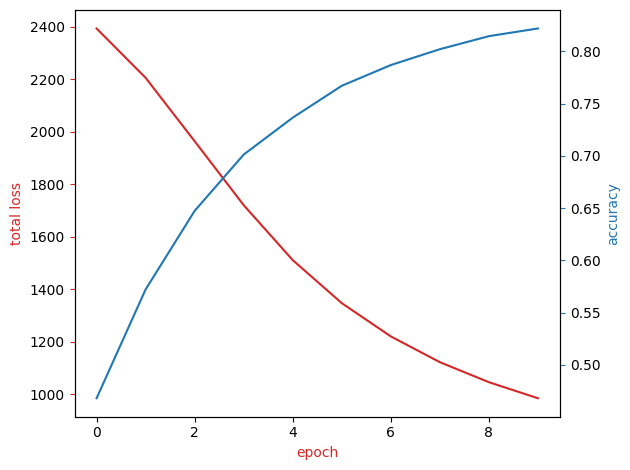

In [ ]:
plot(cum_loss_list,acc_epoch)

In [ ]:
evaluate(test_dataloader)

0.8181578947368421

this is just to generate a 3D t-SNE visualization of embedding using Plotly. It demonstrates how words that are similar to each other are positioned closer together.

In [ ]:
# Get the first batch from the validation data
batch = next(iter(valid_dataloader))

# Extract the text and offsets from the batch
label, text, offsets = batch

# Send the data to the device (GPU if available)
text = text.to(device)
offsets = offsets.to(device)

# Get the embeddings bag output for the batch
embedded = model.embedding(text, offsets)

# Convert the embeddings tensor to a numpy array
embeddings_numpy = embedded.detach().cpu().numpy()

# Perform t-SNE on the embeddings to reduce their dimensionality to 3D.
X_embedded_3d = TSNE(n_components=3).fit_transform(embeddings_numpy)

# Create a 3D scatter plot using Plotly
trace = go.Scatter3d(
    x=X_embedded_3d[:, 0],
    y=X_embedded_3d[:, 1],
    z=X_embedded_3d[:, 2],
    mode='markers',
    marker=dict(
        size=5,
        color=label.numpy(),  # Use label information for color
        colorscale='Viridis',  # Choose a colorscale
        opacity=0.8
    )
)

layout = go.Layout(title="3D t-SNE Visualization of Embeddings",
                   scene=dict(xaxis_title='Dimension 1',
                              yaxis_title='Dimension 2',
                              zaxis_title='Dimension 3'))

fig = go.Figure(data=[trace], layout=layout)
fig.show()

testing the model on unseen data:


In [ ]:
#load the model:
model.load_state_dict(torch.load('my_model.pth'))
model.eval()




TextClassificationModel(
  (embedding): EmbeddingBag(95811, 64, mode='mean')
  (fc): Linear(in_features=64, out_features=4, bias=True)
)

In [ ]:
new_articles = [
    "International talks have made significant headway with the signing of a climate accord that commits countries to reduce emissions by 40% over the next two decades. World leaders expressed optimism at the conclusion of the summit.",
    "In a stunning upset, the underdog team won the national title, beating the favorites in a match that featured an incredible comeback and a last-minute goal that sealed their victory in front of a record crowd.",
    "Market analysts are optimistic as the tech startup's stock prices soared after the announcement of their latest product, which promises to revolutionize how we interact with smart devices.",
    "A recent study published in a leading scientific journal suggests that a new drug has shown promise in the treatment of Alzheimer's disease, outperforming current leading medications in early clinical trials.",
    "Diplomatic relations have taken a positive turn with the recent peace talks that aim to end decades of conflict. The ceasefire agreement has been welcomed by the international community.",
    "Economic indicators show a sharp rebound in manufacturing, with the automobile industry leading the charge. Analysts predict this surge will result in significant job creation over the next year.",
    "Researchers at the university's astrophysics department have discovered a potentially habitable exoplanet. The planet, which lies in a nearby star system, has conditions that could support liquid water and, possibly, life.",
    "The sports world is in shock as a legendary player announces their retirement. Over an illustrious 20-year career, the athlete has amassed numerous records and is regarded as one of the greatest to ever play the game.",
    "A multinational corporation has announced a major investment in renewable energy. The initiative includes the construction of new wind farms and solar panels that will power hundreds of thousands of homes.",
    "Climate scientists warn that the melting of the polar ice caps has been accelerating at an alarming rate, raising sea levels and threatening coastal cities worldwide with increased flooding risks."
]

In [ ]:
for i,art in enumerate(new_articles):

    output= predict(art,text_pipeline)
    print(f"Article {i} is classified as: {output}\n")

Article 0 is classified as: World

Article 1 is classified as: Sports

Article 2 is classified as: Sci/Tec

Article 3 is classified as: Sci/Tec

Article 4 is classified as: Sci/Tec

Article 5 is classified as: Sci/Tec

Article 6 is classified as: Sci/Tec

Article 7 is classified as: Sports

Article 8 is classified as: Sci/Tec

Article 9 is classified as: Sci/Tec

